# `detour_factor` sweep for `DeviatedFixedRoutePolicy`

`DeviatedFixedRoutePolicy` keeps the skip-stop backbone (which caps ride time
~for free via the cycle) and adds **bounded detours** to grab nearby out-of-order
demand. `detour_factor` is the knob: `1.0` reduces exactly to skip-stop; larger
values allow bigger detours, trading a slowly-rising ride tail for better wait
and coverage. Because total deviation per cycle is capped at
`(detour_factor − 1) × cycle`, a rider's ride stays within `detour_factor ×` the
base cycle — so this sweep should hug the **low-max-ride** region, unlike the
`ride_factor` sweep which started from greedy's blown-up ride tail.

Each swept value is its own column, run on the **same demand seeds** as the
baselines. `compare_policies` renders one **tqdm** bar (with ETA) per column.

**What we're testing:** does this frontier *dominate* the RideBounded one — i.e.
reach served ≥ skip-stop's ~72% (ideally toward Nearest's ~74.6%) and mean wait
below skip-stop's ~461s, while **max ride stays near skip-stop's ~1,300s**?

In [1]:
%matplotlib inline

import statistics

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src.algorithm.FixedRoutePolicy import FixedRoutePolicy
from src.algorithm.SkipStopFixedRoutePolicy import SkipStopFixedRoutePolicy
from src.algorithm.NearestUnservedPolicy import NearestUnservedPolicy
from src.algorithm.DeviatedFixedRoutePolicy import DeviatedFixedRoutePolicy
from src.experiment import summarize_comparison
from src.map.PlanarMapProvider import PlanarMapProvider
from src.map.graph import PlanarStreetGraph

In [2]:
MAP_SEED = 42

graph = PlanarStreetGraph.generate(
    n_seeds=17,
    bounds=(0.0, 0.0, 2000.0, 2000.0),
    seed=MAP_SEED,
    stop_density=0.5,
)

provider = PlanarMapProvider(graph)
print(f"{len(provider.get_stops())} bus stops on this map")

21 bus stops on this map


In [3]:
# Swept detour_factor values (edit freely). detour_factor=1.0 == skip-stop,
# which is already a baseline column, so the sweep starts above 1.0.
DETOUR_FACTORS = [1.5, 2.0, 2.5, 3.0]

N_TRIALS = 1000
BASE_SEED = 0

# run_trial kwargs, matching the campus experiment.
TRIAL_KWARGS = dict(max_requests=200, capacity=40, max_wait_s=900.0)

# Baselines (skip-stop = ride-cap anchor, Nearest = coverage anchor) plus one
# DeviatedFixedRoute column per swept factor. The `df=df` default-arg capture
# avoids the late-binding closure bug.
policies = [
    ("Fixed route", lambda g: FixedRoutePolicy(g)),
    ("Fixed route w/ skip", lambda g: SkipStopFixedRoutePolicy(g)),
    ("Nearest unserved", lambda g: NearestUnservedPolicy(g)),
] + [
    (
        f"DFR df={df}",
        lambda g, df=df: DeviatedFixedRoutePolicy(g, detour_factor=df),
    )
    for df in DETOUR_FACTORS
]

summary = summarize_comparison(
    policies=policies,
    graph=graph,
    n_trials=N_TRIALS,
    base_seed=BASE_SEED,
    **TRIAL_KWARGS,
)

display(Markdown(summary.markdown))

Fixed route        :   0%|          | 0/1000 [00:00<?, ?it/s]

Fixed route w/ skip:   0%|          | 0/1000 [00:00<?, ?it/s]

Nearest unserved   :   0%|          | 0/1000 [00:00<?, ?it/s]

DFR df=1.5         :   0%|          | 0/1000 [00:00<?, ?it/s]

DFR df=2.0         :   0%|          | 0/1000 [00:00<?, ?it/s]

DFR df=2.5         :   0%|          | 0/1000 [00:00<?, ?it/s]

DFR df=3.0         :   0%|          | 0/1000 [00:00<?, ?it/s]

| Property | Fixed route | Fixed route w/ skip | Nearest unserved | DFR df=1.5 | DFR df=2.0 | DFR df=2.5 | DFR df=3.0 |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Fulfilled requests | 136.6 (±0.4%) | 141.0 (±0.8%) | 148.5 (±0.8%) | 146.6 (±0.8%) | 145.4 (±0.8%) | 141.7 (±0.8%) | 143.9 (±0.8%) |
| Cancelled requests | 63.0 (±0.7%) | 56.2 (±1.1%) | 48.8 (±1.1%) | 50.6 (±1.1%) | 51.8 (±1.0%) | 55.5 (±1.0%) | 53.3 (±1.0%) |
| Mean wait time | 452.3 s (±0.4%) | 460.0 s (±0.8%) | 366.8 s (±0.8%) | 385.9 s (±0.8%) | 378.6 s (±0.8%) | 379.7 s (±0.8%) | 375.8 s (±0.8%) |
| P90 wait time | 804.9 s (±0.3%) | 795.4 s (±0.8%) | 678.5 s (±0.8%) | 704.8 s (±0.8%) | 696.3 s (±0.8%) | 702.1 s (±0.8%) | 698.4 s (±0.8%) |
| Mean ride time | 654.2 s (±0.4%) | 585.3 s (±0.8%) | 966.6 s (±1.5%) | 1011.1 s (±1.6%) | 1176.6 s (±1.5%) | 1128.1 s (±1.4%) | 947.5 s (±1.3%) |
| Fulfillment rate | 68.5 % (±0.3%) | 71.9 % (±0.4%) | 75.6 % (±0.4%) | 74.7 % (±0.4%) | 74.1 % (±0.4%) | 72.3 % (±0.4%) | 73.3 % (±0.4%) |
| Served fraction | 68.5 % (±0.3%) | 71.9 % (±0.4%) | 75.6 % (±0.4%) | 74.7 % (±0.4%) | 74.1 % (±0.4%) | 72.3 % (±0.4%) | 73.3 % (±0.4%) |
| Throughput | 0.6 req/min (±0.9%) | 0.7 req/min (±3.4%) | 0.7 req/min (±3.2%) | 0.7 req/min (±3.3%) | 0.7 req/min (±3.4%) | 0.7 req/min (±3.5%) | 0.7 req/min (±3.4%) |
| Tick snapshots | 13451.3 (±0.3%) | 12958.5 (±0.7%) | 12857.2 (±0.7%) | 12995.5 (±0.7%) | 13079.4 (±0.7%) | 13098.4 (±0.7%) | 13064.7 (±0.7%) |
| Fulfilled (wait samples) | 136.6 (±0.4%) | 141.0 (±0.8%) | 148.5 (±0.8%) | 146.6 (±0.8%) | 145.4 (±0.8%) | 141.7 (±0.8%) | 143.9 (±0.8%) |
| Min wait time | 6.9 s (±6.1%) | 6.7 s (±6.7%) | 5.4 s (±7.9%) | 6.1 s (±7.1%) | 6.5 s (±7.9%) | 6.1 s (±7.2%) | 6.1 s (±7.6%) |
| Max wait time | 891.5 s (±0.3%) | 880.5 s (±0.7%) | 869.3 s (±0.7%) | 870.6 s (±0.7%) | 870.2 s (±0.7%) | 871.5 s (±0.7%) | 871.0 s (±0.7%) |
| Min ride time | 9.8 s (±4.9%) | 9.7 s (±4.5%) | 8.1 s (±2.3%) | 8.5 s (±3.1%) | 8.4 s (±2.9%) | 8.4 s (±3.0%) | 7.8 s (±3.0%) |
| Max ride time | 1302.8 s (±0.3%) | 1282.0 s (±0.8%) | 9948.3 s (±1.6%) | 9622.5 s (±1.6%) | 11243.7 s (±1.0%) | 11206.9 s (±1.0%) | 10819.1 s (±1.2%) |

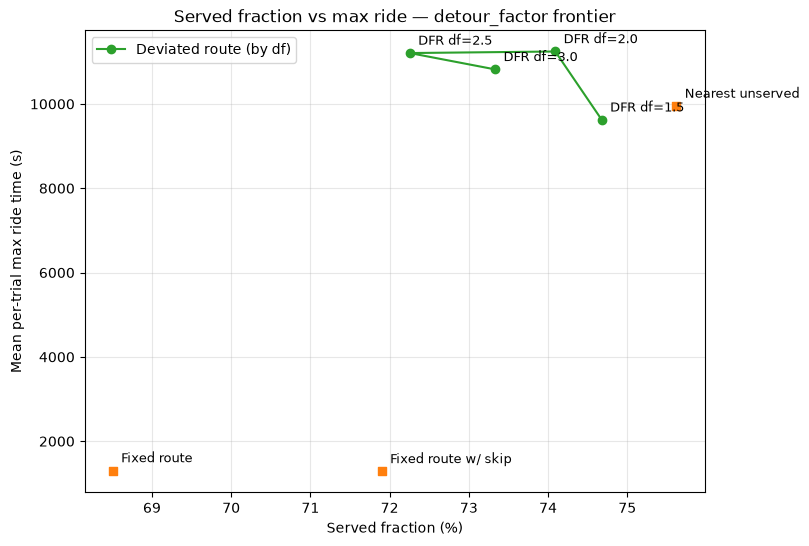

In [4]:
# Frontier: mean served fraction (x) vs mean per-trial max ride (y) per policy.
def _mean_served(trials):
    values = [
        t.kpi.served_fraction
        for t in trials
        if t.kpi.served_fraction is not None
    ]
    return statistics.fmean(values) if values else None


def _mean_max_ride(trials):
    per_trial_max = [max(t.ride_times) for t in trials if t.ride_times]
    return statistics.fmean(per_trial_max) if per_trial_max else None


points = {
    label: (_mean_served(trials), _mean_max_ride(trials))
    for label, trials in summary.results.items()
}
points = {
    label: (served, max_ride)
    for label, (served, max_ride) in points.items()
    if served is not None and max_ride is not None
}

dfr_labels = [f"DFR df={df}" for df in DETOUR_FACTORS if f"DFR df={df}" in points]
baseline_labels = [label for label in points if label not in dfr_labels]

fig, ax = plt.subplots(figsize=(8, 6))

# Deviated-route frontier: connect points in detour_factor order.
dfr_x = [points[label][0] * 100.0 for label in dfr_labels]
dfr_y = [points[label][1] for label in dfr_labels]
ax.plot(dfr_x, dfr_y, "-o", color="tab:green", label="Deviated route (by df)")

# Baselines as separate markers.
for label in baseline_labels:
    served, max_ride = points[label]
    ax.scatter(served * 100.0, max_ride, marker="s", color="tab:orange", zorder=3)

for label, (served, max_ride) in points.items():
    ax.annotate(
        label,
        (served * 100.0, max_ride),
        textcoords="offset points",
        xytext=(6, 6),
        fontsize=9,
    )

ax.set_xlabel("Served fraction (%)")
ax.set_ylabel("Mean per-trial max ride time (s)")
ax.set_title("Served fraction vs max ride — detour_factor frontier")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## Reading the frontier

- **The win condition:** the green `DFR df=…` points should sit **low** (near
  skip-stop's max ride, far below the RideBounded frontier's 4,000–10,000s) while
  pushing **right** (higher served fraction) and — check the table — cutting mean
  wait below skip-stop's ~461s. A DFR point that is at or right of skip-stop on
  served *and* below it on wait, with only a modest max-ride increase, is a
  strict improvement over skip-stop and the first policy to genuinely beat the
  skip-vs-Nearest front.
- **If the green points barely move right of skip-stop**, detours aren't finding
  much reachable out-of-order demand at this scale/geometry — the backbone
  already visits stops in near-optimal order (a real possibility on a compact
  campus map), and skip-stop stands as the answer.
- **If max ride climbs steeply with detour_factor**, tighten the knob (smaller
  detour_factor) — the value is in the low-df region that keeps rides bounded.
- Compare directly against the `ride_factor` sweep: the whole thesis is that
  attacking from the fixed-route side lands in the low-max-ride corner that
  RideBounded could never reach.